In [20]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay
)

Load dataset

In [21]:
df = pd.read_csv("Mall_Customers.csv")

Basic inspection

In [22]:
print(df.head())
print("\n")
print(df.shape)
print("\n")
print(df.info())
print("\n")

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


(200, 5)


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None




Define binary classification target

In [23]:
df["HighSpender"] = (df["Spending Score (1-100)"] >= 50).astype(int)

In [24]:
feature_cols = ["Gender", "Age", "Annual Income (k$)"]
X = df[feature_cols]
y = df["HighSpender"]

categorical_features = ["Gender"]
numeric_features = ["Age", "Annual Income (k$)"]

Preprocess numeric and categorical features

In [25]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
         categorical_features),
    ],
    remainder="drop"
)

Build a reproducible pipeline

In [26]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

Split data into training and test sets

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

Evaluate with stratified 5-fold cross-validation on training data.

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results = cross_validate(
    model, X_train, y_train, cv=cv, scoring=scoring,
    return_train_score=False
)

print("5-fold cross-validation (mean scores):")
for metric in scoring:
    values = cv_results[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} (+/- {values.std(ddof=1):.3f})")

5-fold cross-validation (mean scores):
accuracy: 0.625 (+/- 0.049)
precision: 0.615 (+/- 0.043)
recall: 0.721 (+/- 0.086)
f1: 0.662 (+/- 0.053)
roc_auc: 0.647 (+/- 0.077)


Fit the final model and predict the held-out test set.

In [29]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

Report test-set matrix

In [30]:
print("Test-set evaluation:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}\n")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}\n")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}\n")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}\n")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.3f}\n")

print("Classification report:")
print(classification_report(
    y_test, y_pred, target_names=["Not high spender", "High spender"],
    zero_division=0
))


Test-set evaluation:
Accuracy:  0.725

Precision: 0.737

Recall:    0.700

F1-score:  0.718

ROC-AUC:   0.680

Classification report:
                  precision    recall  f1-score   support

Not high spender       0.71      0.75      0.73        20
    High spender       0.74      0.70      0.72        20

        accuracy                           0.72        40
       macro avg       0.73      0.72      0.72        40
    weighted avg       0.73      0.72      0.72        40



Confusion Matrix

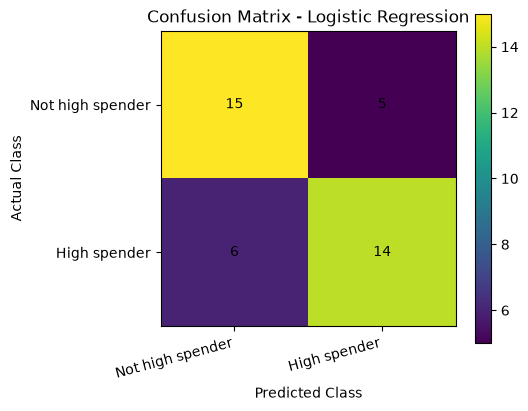

In [31]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix - Logistic Regression")
plt.colorbar()
plt.xticks([0, 1], ["Not high spender", "High spender"], rotation=15, ha="right")
plt.yticks([0, 1], ["Not high spender", "High spender"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.ylabel("Actual Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

ROC curve

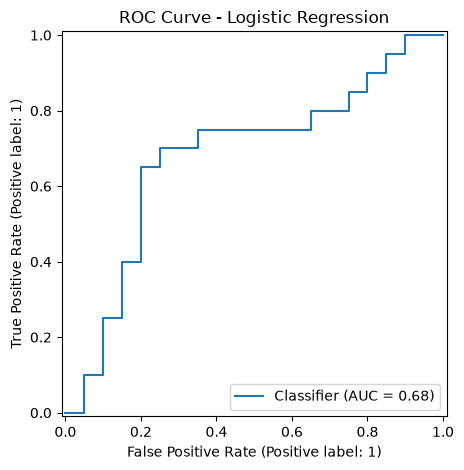

In [32]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve - Logistic Regression")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

Inspect coefficients for inerpretability.

In [33]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
}).sort_values("Coefficient", ascending=False)

In [34]:
print("Model coefficients (log-odds scale):")
print(coefficient_table.to_string(index=False))

Model coefficients (log-odds scale):
                Feature  Coefficient
num__Annual Income (k$)    -0.012292
       cat__Gender_Male    -0.018625
               num__Age    -0.591017


Save reproducible evaluation outputs.

In [35]:
evaluation = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Test Set": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_proba),
    ],
})
evaluation.to_csv("model_evaluation_metrics.csv", index=False)

predictions = X_test.copy()
predictions["Actual_HighSpender"] = y_test.values
predictions["Predicted_HighSpender"] = y_pred
predictions["Predicted_Probability"] = y_proba
predictions.to_csv("test_predictions.csv", index=False)


In [36]:
print("\\nSaved model_evaluation_metrics.csv and test_predictions.csv.")

\nSaved model_evaluation_metrics.csv and test_predictions.csv.
